In [1]:
import numpy as np
import matplotlib.pyplot as plt
import utils

from scipy.interpolate import InterpolatedUnivariateSpline as spline
from astropy.cosmology import Planck15

from tqdm import tqdm

import seaborn as sns
from popsummary.popresult import PopulationResult

In [2]:
from gwbench import antenna_pattern_np as antpat
from gwbench.wf_models import lal_bbh_np as lal_bbh
from gwbench import psd
from gwbench import snr
import gwbench.utils


/home/alexandretoubiana/anaconda3/envs/env1/lib/python3.13/site-packages/gwbench/basic_relations.py:20: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import GreenwichMeanSiderealTime


In [3]:
# 

In [18]:
f_lo = 16
f_hi = 2048
df = 2**-4
f = np.arange(f_lo, f_hi, df)

ra_s = gwbench.utils.det_specs_built_in['H']['longitude'] + gwbench.utils.tc_offset * 2*np.pi / gwbench.utils.det_specs_built_in['H']['period']
dec_s = gwbench.utils.det_specs_built_in['H']['latitude']

m1_interp_min,m1_interp_max=2.,500.
m2_interp_min,m2_interp_max=2.,500.

zmax=2.5

Dfix=500

# large_snr=1
injections_pop=1
log_normal_pop=0
delta_pop=0
injections_flat_z=0
more_inj=1

In [ ]:
# f_lo = 16
# f_hi = 2048
# df = 2**-4
# f = np.arange(f_lo, f_hi, df)


# zmax=5

# ngrid=200
# m1s_grid=np.linspace(m1_interp_min,m1_interp_max,ngrid)
# m2s_grid=np.linspace(m2_interp_min,m2_interp_max,ngrid)


# snrs_grid=np.zeros((len(m1s_grid),len(m2s_grid)))

# Dfix=500

# for i in tqdm(range(ngrid)):
#     m1i=m1s_grid[i]
#     for j in tqdm(range(0,i+1)):

#         # print(j)

#         m2j=m2s_grid[j]

#         # print(m1i,m2j)

#         chirpmij=((m1i**3*m2j**3)/(m1i+m2j))**(1./5.)

#         etaij=m1i*m2j/((m1i+m2j)**2)


#         Mc = chirpmij #chirp mass
#         eta = etaij #symmetric mass ratio
#         chi1x = 0. #spin 1 x
#         chi1y = 0. #spin 1 y
#         chi1z = 0. #spin 1 z
#         chi2x = 0. #spin 2 x
#         chi2y = 0. #spin 2 y
#         chi2z = 0. #spin 2 z
#         DL = Dfix #distance in Mpc
#         iota = 0. #inclination
#         tc = 0 #coalescence time
#         phic = 0 #phase at coalescence
#         ra = ra_s #right ascension
#         dec = dec_s #declination
#         psi = 0 #polarisation
#         gmst0 = 0
#         use_rot = 0

#         approximant = 'IMRPhenomXPHM'
#         hfp, hfc = lal_bbh.hfpc(f, Mc, eta, chi1x, chi1y, chi1z, chi2x, chi2y, chi2z, DL, tc, phic, iota, approximant=approximant)
#         det_psd_ET, ff = psd.psd('aLIGO', f, f_lo=f_lo, f_hi=f_hi)

#         locs = ['H']
#         snr_sq = 0
#         for loc in locs:
#             hf = antpat.detector_response(hfp, hfc, f, Mc, eta, tc, ra, dec, psi, loc, use_rot, user_locs=None)
            
#             snr_sq += snr.snr_square(hf, det_psd_ET, ff)

#         # print(i,j,np.sqrt(snr_sq))
#         snrs_grid[i,j] = np.sqrt(snr_sq)
#         snrs_grid[j,i] = np.sqrt(snr_sq)

100%|██████████| 200/200 [09:54<00:00,  2.97s/it]


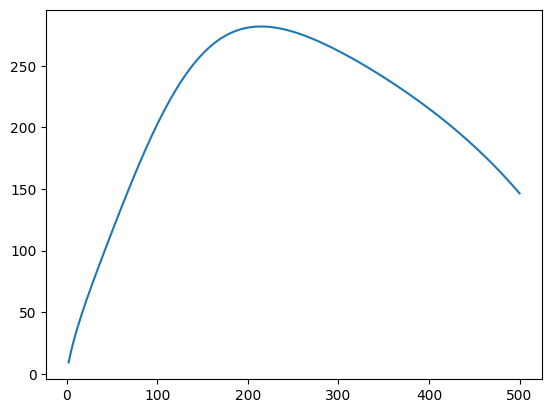

In [21]:

plt.plot(m1s_grid,snrs_grid[np.arange(ngrid),np.arange(ngrid)])

In [ ]:

# np.savez('grid_snr.npz',m1s_grid=m1s_grid,m2s_grid=m2s_grid,snrs_grid=snrs_grid,Dfix=Dfix)

In [ ]:
# print(m1s_grid[-1],m2s_grid[-1],snrs_grid[-1,-1])

In [25]:
file=np.load('grid_snr.npz')
m1s_grid=file['m1s_grid']
m2s_grid=file['m2s_grid']
snrs_grid=file['snrs_grid']



In [26]:
from scipy.interpolate import RegularGridInterpolator

snr_interp=RegularGridInterpolator([m1s_grid,m2s_grid],snrs_grid)

In [27]:
def draw_thetas(N):
   
    cos_thetas = np.random.uniform(-1, 1, N)
    cos_incs = np.random.uniform(-1, 1, N)
    phis = np.random.uniform(0, 2*np.pi, N)
    zetas = np.random.uniform(0, 2*np.pi, N)

    Fps1 = 0.5*np.cos(2*zetas)*(1 + cos_thetas**2)*np.cos(2*phis) - np.sin(2*zetas)*cos_thetas*np.sin(2*phis)
    Fxs1 = 0.5*np.sin(2*zetas)*(1 + cos_thetas**2)*np.cos(2*phis) + np.cos(2*zetas)*cos_thetas*np.sin(2*phis)

    return np.sqrt(0.25*(Fps1**2)*(1 + cos_incs**2)**2 + (Fxs1**2)*cos_incs**2)


In [28]:
filename = "BBHMassSpinRedshift_BrokenPowerLawTwoPeaks_GaussianComponentSpins_PowerLawRedshift.h5"
result = PopulationResult(fname=filename)

hyper_samples=result.get_hyperparameter_samples(hyperparameters=['alpha_1', 'alpha_2' , 'break_mass', 'delta_m_1', 'lam_0', 'lam_1', 'lamb', 'mlow_1', 'mpp_1', 'sigpp_1' , 'mpp_2', 'sigpp_2', 'beta'])

params={}

id_sample=-3

params['alpha_1']=hyper_samples[id_sample,0]
params['alpha_2']=hyper_samples[id_sample,1]
params['m_break']=hyper_samples[id_sample,2]
params['m1_low']=hyper_samples[id_sample,7]
params['m1_high']=200.
params['mu_1']=hyper_samples[id_sample,8]
params['sigma_1']=hyper_samples[id_sample,9] 
params['mu_2'] = hyper_samples[id_sample,10] 
params['sigma_2'] = hyper_samples[id_sample,11] 
params['lamda_0'] = hyper_samples[id_sample,4] 
params['lamda_1'] = hyper_samples[id_sample,5] 
params['delta_m1'] = hyper_samples[id_sample,3] 

params['kappa']=hyper_samples[id_sample,6] 

# params['betaq']=hyper_samples[id_sample,12] 
params['betaq']=4

params['mg_low']=45
params['mg_up']=115

zmax=1.5

settings={}

settings['zmin'],settings['zmax']=0,zmax
zs_grid=np.linspace(0,zmax,1000)
dVc=np.copy(Planck15.differential_comoving_volume(zs_grid))*4.*np.pi
dVc_spl=spline(zs_grid,dVc)

settings['dVc_spl']=dVc_spl

dls=np.copy(Planck15.luminosity_distance(zs_grid))
zs_dl_spline=spline(dls,zs_grid)
dl_zs_spline=spline(zs_grid,dls)
ddl_zs_spline=dl_zs_spline.derivative()



snr_th=8


ninj=100000000

if injections_pop==1 or injections_flat_z==1:
    ninj=1000000
    # ninj=10000

if more_inj==1:
    ninj*=3

elif more_inj==2:
    ninj*=10

zs_grid=np.linspace(0,zmax,1000)
dVc=np.copy(Planck15.differential_comoving_volume(zs_grid))*4.*np.pi
dVc_spl=spline(zs_grid,dVc)

dls=np.copy(Planck15.luminosity_distance(zs_grid))
zs_dl_spline=spline(dls,zs_grid)
dl_zs_spline=spline(zs_grid,dls)
ddl_zs_spline=dl_zs_spline.derivative()

theta_max=np.sqrt(3)


In [39]:

seed=0

np.random.seed(seed)



print('drawing')


if injections_pop==1 :
    # num_inj_1=np.random.binomial(ninj, params['mix_coeff'])
    # num_inj_2=ninj-num_inj_1

    # zs_inj0=np.zeros(ninj)

    # zs_inj0[:num_inj_1]=utils.draw_z_merge(num_inj_1,utils.draw_delay_pl,settings,params) 
    # zs_inj0[num_inj_1:]=utils.draw_z_merge(num_inj_2,utils.draw_delta_delay,settings,params)
 
       
    print('drawing m1')
    m1s_inj0=utils.draw_pl(ninj,-params['alpha_1'],params['m1_low'],params['m1_high'])
    print('drawing q')
    qs_inj0=utils.draw_q_no_gap(ninj,m1s_inj0,params['m1_low'],params['betaq'])
    m2s_inj0=m1s_inj0*qs_inj0

    print('drawing z')
    zs_inj0=utils.draw_z_cdf(ninj,params['kappa'],settings['dVc_spl'],settings['zmax'])


thetas_inj0=draw_thetas(ninj)

dls_injs=dl_zs_spline(zs_inj0)

print(np.amax(m1s_inj0*(1+zs_inj0)))
snrs_inj0=snr_interp(np.array([m1s_inj0*(1+zs_inj0),m2s_inj0*(1+zs_inj0)]).T)*thetas_inj0*Dfix/dls_injs


snrs_inj=snrs_inj0+np.random.normal(0,1,ninj)

mtots_inj0=m1s_inj0+m2s_inj0
qs_inj0=m2s_inj0/m1s_inj0

zs_inj=zs_inj0[snrs_inj>snr_th]
m1s_inj=m1s_inj0[snrs_inj>snr_th]
qs_inj=qs_inj0[snrs_inj>snr_th]

print('computing priors')

if injections_pop==1:

    pdf_m1=utils.power_law_pdf(m1s_inj,-params['alpha_1'],params['m1_low'],params['m1_high'])

    pdf_z=utils.z_pdf(zs_inj,params['kappa'],settings['dVc_spl'],settings['zmax'])

    pdf_q=utils.pdf_q_no_gap(qs_inj,m1s_inj,params['m1_low'],params['betaq'])

   

    priors_inj=pdf_m1*pdf_z*pdf_q/m1s_inj



drawing
drawing m1
drawing q
drawing z
499.21159790585205
computing priors


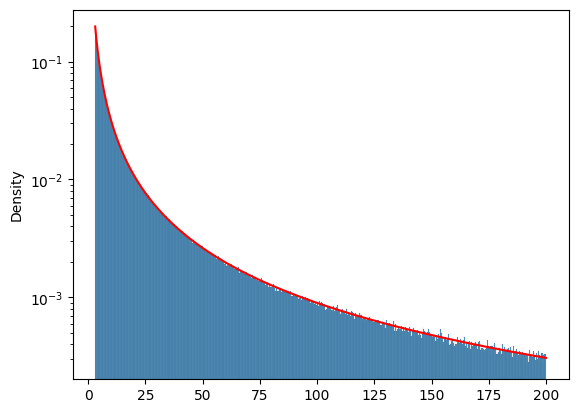

In [44]:
# print(len(events0_inj))
sns.histplot(m1s_inj0,stat='density')
plt.plot(np.sort(m1s_inj),pdf_m1[np.argsort(m1s_inj)],c='r')
plt.yscale('log')

In [49]:
# # print(len(events0_inj))
# sns.histplot(qs_inj0,stat='density')
# plt.plot(np.sort(qs_inj),np.trapz(pdf_q[np.argsort(qs_inj)]*pdf_m1[np.argsort(m1s_inj)],x=np.sort(m1s_inj)),c='r')
# plt.yscale('log')

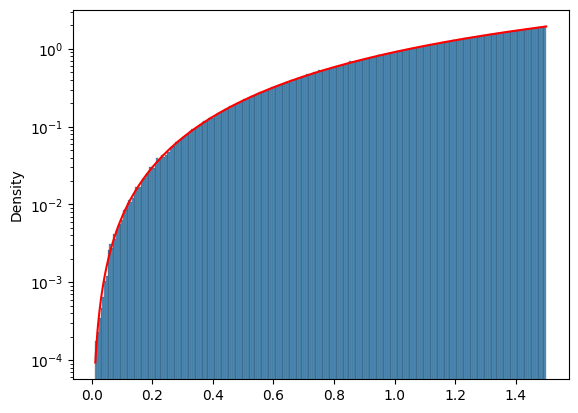

In [47]:
# print(len(events0_inj))
sns.histplot(zs_inj0,stat='density')
plt.plot(np.sort(zs_inj),pdf_z[np.argsort(zs_inj)],c='r')
plt.yscale('log')

In [50]:
name_file_injections='injections/injections'


name_file_injections+='_snr_th_%d'%snr_th

if injections_pop==1:
    name_file_injections+='_injections_pop'


if injections_flat_z==1:
    name_file_injections+='_flat_z'    

# if large_snr==1:
#     name_file_injections+='_large_snr'


name_file_injections+='_zmax_%1.1f'%zmax

if more_inj==1:
    name_file_injections+='_more_inj'

if more_inj==2:
    name_file_injections+='_more_inj2'

np.savez(name_file_injections+'.npz',m1s_inj=m1s_inj,m2s_inj=m1s_inj*qs_inj,zs_inj=zs_inj,priors_inj=priors_inj,ninj=ninj)
# np.savez(name_file_injections+'_seed_%d.npz'%seed,mtots_inj=mtots_inj,qs_inj=qs_inj,zs_inj=zs_inj,priors_inj=priors_inj,ninj=ninj)


In [ ]:
# print(name_file_injections)
# print(len(zs_inj))

injections/injections_pop_alpha_1.5_zmax_3.0_more_inj
230822


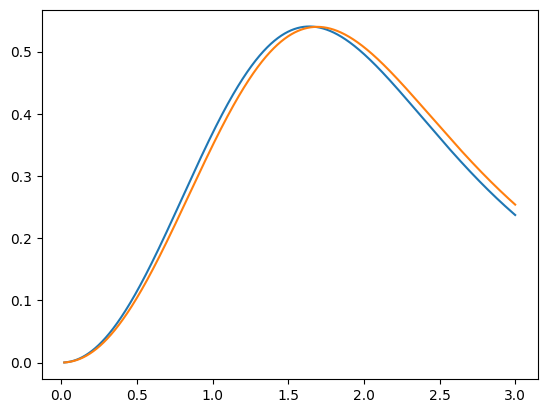

In [ ]:
# plt.plot(np.sort(zs_inj),pdf_z_1[np.argsort(zs_inj)])
# plt.plot(np.sort(zs_inj),pdf_z_2[np.argsort(zs_inj)])



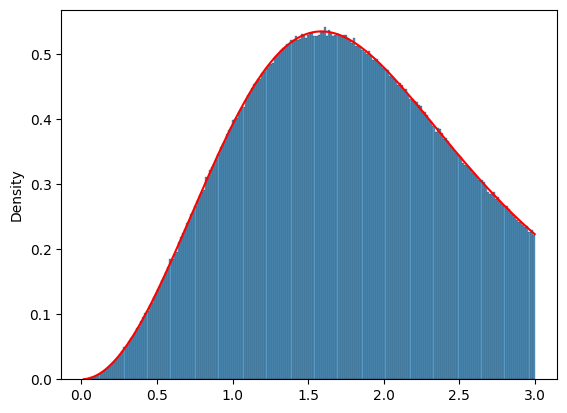

In [ ]:
# sns.histplot(zs_inj0,stat='density')
# plt.plot(np.sort(zs_inj),0.5*(pdf_z_1[np.argsort(zs_inj)]+pdf_z_2[np.argsort(zs_inj)]),c='r')

0.9999494421481663


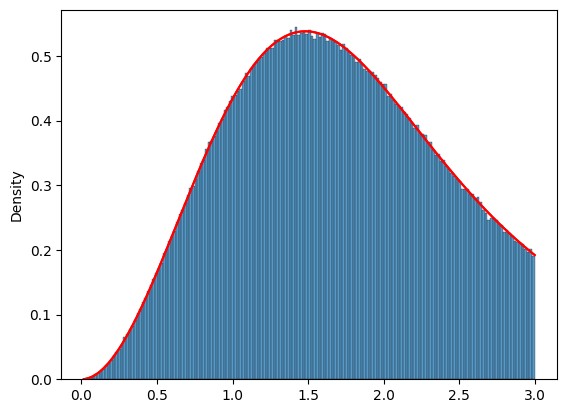

In [ ]:
# sns.histplot(zs_inj0[:num_events_inj_1],stat='density')
# plt.plot(np.sort(zs_inj),pdf_z_1[np.argsort(zs_inj)],c='r')
# plt.plot(np.sort(zs_inj),pdf_z_1[np.argsort(zs_inj)]/np.trapezoid(pdf_z_1[np.argsort(zs_inj)],x=np.sort(zs_inj)),c='r')

# print(np.trapezoid(pdf_z_1[np.argsort(zs_inj)],x=np.sort(zs_inj)))


In [ ]:
# zgrid=np.linspace(0,zmax,1000)
# tgrid=settings['lkbk_time_z_spl'](zgrid)

# points=settings['lkbk_time_z_spl'](zgrid)+params['tdelay_1']*1e-3
# zmins=settings['z_lkbk_time_spl'](params['tdelay_1']*1e-3)
# settings2=settings.copy()
# # settings2['zmax_form']=settings['z_lkbk_time_spl'](settings['lkbk_time_z_spl'](settings['zmax'])+params['tdelay_1']*1e-3)
# print(settings2['zmax_form'])

# pdf_t_1=utils.pdf_t_form(points,settings2,norm=True,zmin=zmins)

# zgrid2=np.linspace(0,20,1000)
# # plt.plot(tgrid,pdf_t_1)
# plt.plot(zgrid2,utils.pdf_z_form(zgrid2,settings,norm=True))

# zforms=utils.draw_z_form(1000,settings)





# sns.histplot(zforms,stat='density')

KeyError: 'tdelay_1'

In [ ]:
ts=np.linspace(0,settings['lkbk_time_z_spl'](20),1000)
pdf_t_forms=utils.pdf_t_form(points,settings,norm=True,zmin=0)
# print(pdf_t_forms)
plt.plot(ts,pdf_t_forms)

tforms=settings['lkbk_time_z_spl'](zforms)

sns.histplot(tforms,stat='density')

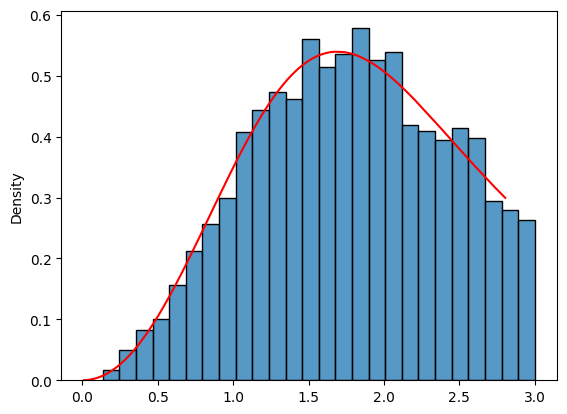

In [ ]:
# sns.histplot(zs_inj0[num_events_inj_1:],stat='density')
# plt.plot(np.sort(zs_inj),pdf_z_2[np.argsort(zs_inj)],c='r')

<Axes: >

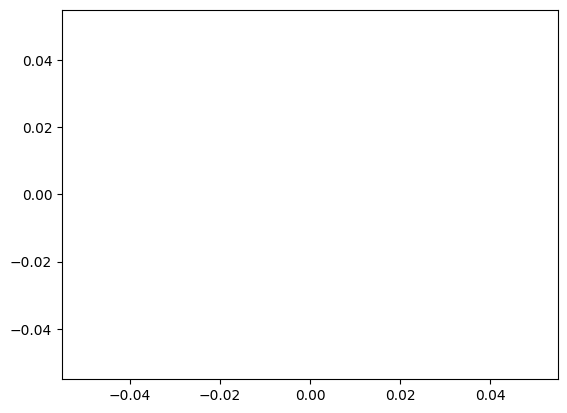

In [ ]:
# sns.histplot(zs_inj[num_events_inj_1:],stat='density')

In [ ]:
# 

injections/injections_delta_pop_large_snr_zmax_3.0_more_inj


In [ ]:
# print(np.amax(zs_inj))

2.962201874966582


193247
415259.70028400957


/tmp/ipykernel_13807/3289515087.py:1: RuntimeWarning: invalid value encountered in log10
  plt.hist(np.log10(snrs_inj))


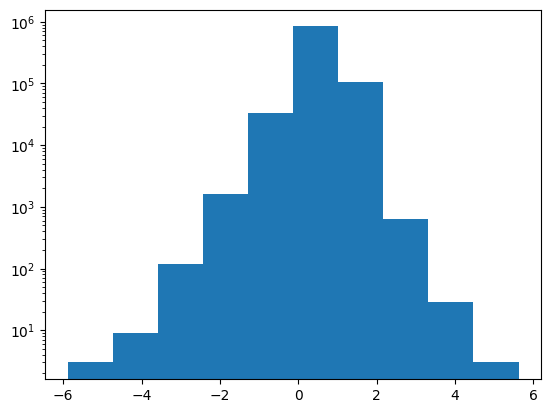

In [ ]:
# plt.hist(np.log10(snrs_inj))
# plt.yscale('log')

# print(np.sum(snrs_inj>snr_th))
# print(np.amax(snrs_inj))

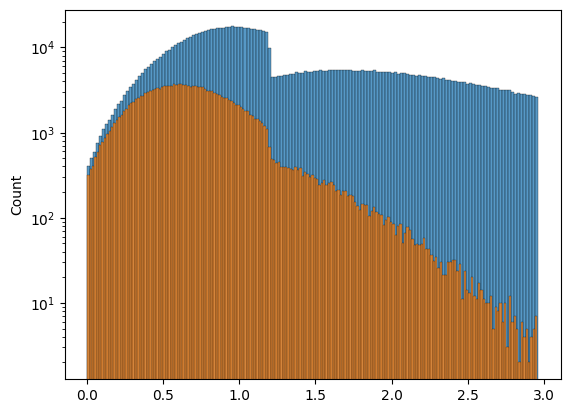

In [ ]:

# sns.histplot(zs_inj0)
# sns.histplot(zs_inj)
# plt.yscale('log')

In [ ]:
import seaborn as sns
sns.histplot(zs_inj0[:20000],stat='density')
plt.plot(zs_grid,pdf_z_1_spline(zs_grid))

In [ ]:
# small_errors=0
# sample_in_q=1
# more_events=1
# injections_pop=1

# num_events = 1000
# if more_events==1:
#     num_events=3000

# events0,num_events_1=utils.draw_events(num_events,params,settings)

# if small_errors==0:
#     sigma0_chirpm=0.08*snr_th
#     sigma0_eta=0.022*snr_th
#     sigma0_q=0.07*snr_th
#     sigma0_theta=0.21*snr_th

# elif small_errors==1:
#     sigma0_chirpm=0.008*snr_th
#     sigma0_eta=0.0022*snr_th
#     sigma0_q=0.007*snr_th
#     sigma0_theta=0.021*snr_th

# nsamples_ev=5000

# zs_events0=events0[:,2]
# dl_events0=dl_zs_spline(zs_events0)
# mtots_events0=events0[:,0]
# qs_events0=events0[:,1]
# m1s_events0=mtots_events0/(1.+qs_events0)
# m2s_events0=mtots_events0*qs_events0/(1.+qs_events0)
# chirpmz_events0=(1.+zs_events0)*((m1s_events0**3*m2s_events0**3)/(m1s_events0+m2s_events0))**(1./5.)
# eta_events0=m1s_events0*m2s_events0/((m1s_events0+m2s_events0)**2)
# theta_events0=draw_thetas(len(zs_events0))

# snrs0=snr_interp(np.array([m1s_events0*(1.+zs_events0),m2s_events0*(1.+zs_events0)]).T)*theta_events0*Dfix/dl_events0

# snrs=snrs0+np.random.normal(0,1,len(snrs0))
# # nfix=np.sum(snrs<0.)
# # while nfix>0:
# #     inds_fix=np.argwhere(snrs<0)[:,0]

# #     snrs[inds_fix]=snrs0[inds_fix]+np.random.normal(0,1,nfix)

# #     nfix=np.sum(snrs<0)

# det_mask=snrs>snr_th

# snrs_obs0=snrs[det_mask]

# print('nobs is:',len(snrs_obs0))

# chirpmz_events=chirpmz_events0[det_mask]
# chirpmz_obs0=chirpmz_events+np.random.normal(0,1,len(snrs_obs0))*(sigma0_chirpm/snrs_obs0)
# # nfix=np.sum(chirpmz_obs0<0.)
# # while nfix>0:
# #     inds_fix=np.argwhere(chirpmz_obs0<0)[:,0]

# #     chirpmz_obs0[inds_fix]=chirpmz_events[inds_fix]+np.random.normal(0,1,nfix)*(sigma0_chirpm/snrs_obs0[inds_fix])

# #     nfix=np.sum(chirpmz_obs0<0.)

# if sample_in_q==0:
#     eta_events=eta_events0[det_mask]
#     eta_obs0=eta_events+np.random.normal(0,1,len(snrs_obs0))*(sigma0_eta/snrs_obs0)
# else:
#     qs_events=qs_events0[det_mask]
#     q_obs0=qs_events+np.random.normal(0,1,len(snrs_obs0))*(sigma0_q/snrs_obs0)

# # nfix=np.sum((eta_obs0<0.) | (eta_obs0>0.25))
# # while nfix>0:
# #     inds_fix=np.argwhere((eta_obs0<0.) | (eta_obs0>0.25))[:,0]

# #     eta_obs0[inds_fix]=eta_events[inds_fix]+np.random.normal(0,1,nfix)*(sigma0_eta/snrs_obs0[inds_fix])

# #     nfix=np.sum((eta_obs0<0.) | (eta_obs0>0.25))

# theta_events=theta_events0[det_mask]
# theta_obs0=theta_events+np.random.normal(0,1,len(snrs_obs0))*(sigma0_theta/snrs_obs0)
# # nfix=np.sum((theta_obs0<0.) | (theta_obs0>1.))
# # while nfix>0:
# #     inds_fix=np.argwhere((theta_obs0<0) | (theta_obs0>1.))[:,0]

# #     theta_obs0[inds_fix]=theta_events[inds_fix]+np.random.normal(0,1,nfix)*(sigma0_theta/snrs_obs0[inds_fix])

# #     nfix=np.sum((theta_obs0<0.) | (theta_obs0>1.))



# print('doing snr samples')
# snrs_obs=np.repeat(snrs_obs0,nsamples_ev)+np.random.normal(0,1,nsamples_ev*len(snrs_obs0))
# nfix=np.sum(snrs_obs<0.)
# while nfix>0:
#     inds_fix=np.argwhere(snrs_obs<0)[:,0]

#     snrs_obs[inds_fix]=np.repeat(snrs_obs0,nsamples_ev)[inds_fix]+np.random.normal(0,1,nfix)

#     nfix=np.sum(snrs_obs<0.)

# print('doing chirpm samples')
# chirpmz_obs=np.repeat(chirpmz_obs0,nsamples_ev)+np.random.normal(0,1,nsamples_ev*len(snrs_obs0))*(sigma0_chirpm/np.repeat(snrs_obs0,nsamples_ev))
# nfix=np.sum(chirpmz_obs<0.)
# while nfix>0:
#     inds_fix=np.argwhere(chirpmz_obs<0)[:,0]

#     chirpmz_obs[inds_fix]=np.repeat(chirpmz_obs0,nsamples_ev)[inds_fix]+np.random.normal(0,1,nfix)*(sigma0_chirpm/np.repeat(snrs_obs0,nsamples_ev)[inds_fix])

#     nfix=np.sum(chirpmz_obs<0.)

# if sample_in_q==0:
#     print('doing eta samples')
#     eta_obs=np.repeat(eta_obs0,nsamples_ev)+np.random.normal(0,1,nsamples_ev*len(snrs_obs0))*(sigma0_eta/np.repeat(snrs_obs0,nsamples_ev))
#     nfix=np.sum((eta_obs<0.) | (eta_obs>0.25))
#     while nfix>0:
#         inds_fix=np.argwhere((eta_obs<0.) | (eta_obs>0.25))[:,0]

#         eta_obs[inds_fix]=np.repeat(eta_obs0,nsamples_ev)[inds_fix]+np.random.normal(0,1,nfix)*(sigma0_eta/np.repeat(snrs_obs0,nsamples_ev)[inds_fix])

#         nfix=np.sum((eta_obs<0.) | (eta_obs>0.25))
# else:
#     print('doing q samples')
#     q_obs=np.repeat(q_obs0,nsamples_ev)+np.random.normal(0,1,nsamples_ev*len(snrs_obs0))*(sigma0_q/np.repeat(snrs_obs0,nsamples_ev))
#     nfix=np.sum((q_obs<0.) | (q_obs>1.))
#     while nfix>0:
#         inds_fix=np.argwhere((q_obs<0.) | (q_obs>1.))[:,0]

#         q_obs[inds_fix]=np.repeat(q_obs0,nsamples_ev)[inds_fix]+np.random.normal(0,1,nfix)*(sigma0_q/np.repeat(snrs_obs0,nsamples_ev)[inds_fix])

#         nfix=np.sum((q_obs<0.) | (q_obs>1.))

#     eta_obs=q_obs/((1.+q_obs)**2)


# print('doing theta samples')
# theta_obs=np.repeat(theta_obs0,nsamples_ev)+np.random.normal(0,1,nsamples_ev*len(snrs_obs0))*(sigma0_theta/np.repeat(snrs_obs0,nsamples_ev))
# nfix=np.sum((theta_obs<0.) | (theta_obs>1.))
# while nfix>0:
#     inds_fix=np.argwhere((theta_obs<0) | (theta_obs>1.))[:,0]

#     theta_obs[inds_fix]=np.repeat(theta_obs0,nsamples_ev)[inds_fix]+np.random.normal(0,1,nfix)*(sigma0_theta/np.repeat(snrs_obs0,nsamples_ev)[inds_fix])

#     nfix=np.sum((theta_obs<0.) | (theta_obs>1.))


# print('converting')
# mtotz_obs = chirpmz_obs / (eta_obs**(3/5))
    
# # mass ratio factor
# sqrt_term = np.sqrt(1 - 4*eta_obs)

# m1z_obs=0.5 * mtotz_obs * (1 + sqrt_term)
# m2z_obs=0.5 * mtotz_obs * (1 - sqrt_term)


# dl_obs=(snr_interp(np.array([m1z_obs,m2z_obs]).T)*theta_obs/snrs_obs)*Dfix

# # denom_prior_reweight=(snrs_obs/dl_obs)*(m1z_obs-m2z_obs)*eta_obs**(3./5.)/((m1z_obs+m2z_obs)**2.)

# # prior_reweight=dl_obs**2/denom_prior_reweight


# # inds_keep=np.random.choice(np.arange(len(dl_obs)),prior_reweight,replace=False)


# # m1_obs




# z_obs=zs_dl_spline(dl_obs)

# m1_obs=m1z_obs/(1+z_obs)
# m2_obs=m2z_obs/(1+z_obs)

# mtot_obs=m1_obs+m2_obs
# q_obs=m2_obs/m1_obs


# print('computing prior')
# if sample_in_q==0:
#     priors=np.absolute((snrs_obs/dl_obs)*ddl_zs_spline(z_obs)*(1+z_obs)*(m1z_obs-m2z_obs)*m1z_obs**2*eta_obs**(3./5.)/((m1z_obs+m2z_obs)**3)) 
# else:
#     priors=np.absolute((snrs_obs/dl_obs)*ddl_zs_spline(z_obs)*(1+z_obs)*eta_obs**(3./5.)) 

# events=np.zeros((len(chirpmz_events),3))
# events[:,0]=mtots_events0[det_mask]
# events[:,1]=qs_events0[det_mask]
# events[:,2]=zs_events0[det_mask]


# events_obs0=np.zeros((len(chirpmz_events),3))
# events_obs0[:,0]=chirpmz_obs0
# if sample_in_q==0:
#     events_obs0[:,1]=eta_obs0
# elif sample_in_q==1:
#     events_obs0[:,1]=q_obs0
# events_obs0[:,2]=snrs_obs0

nobs is: 257
doing snr samples
doing chirpm samples
doing q samples
doing theta samples
converting
computing prior


In [ ]:
# print(np.amin(z_obs),np.amax(z_obs))
# print(np.amin(m1_obs),np.amax(m1_obs))
# print(np.amin(m2_obs),np.amax(m2_obs))
# print(np.amin(mtot_obs),np.amax(mtot_obs))
# print(np.amin(q_obs),np.amax(q_obs))

# print(np.sum(m2_obs<0.5))

4.9913128067206404e-06 3.6151022082194686
0.7476231026622665 5.76043510083187
0.6134052275906181 4.5092137698207555
1.4479424842930004 9.700664440578326
0.23160739192567428 1.0
0


(array([  20.,  126.,  409.,  893., 1357., 1262.,  638.,  239.,   53.,
           3.]),
 array([0.00278303, 0.17386195, 0.34494087, 0.51601978, 0.6870987 ,
        0.85817762, 1.02925654, 1.20033545, 1.37141437, 1.54249329,
        1.7135722 ]),
 <BarContainer object of 10 artists>)

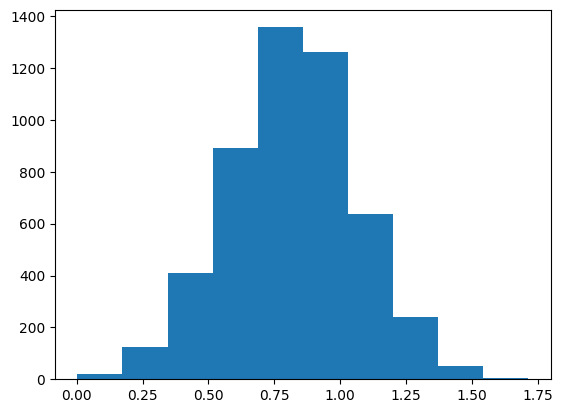

In [ ]:
# z_samples=z_obs.reshape(len(snrs_obs0),nsamples_ev)

# idx=0

# plt.hist(z_samples[idx])

(array([30., 38., 46., 31., 52., 33., 15.,  7.,  2.,  3.]),
 array([0.09403754, 0.29458083, 0.49512412, 0.69566741, 0.8962107 ,
        1.09675399, 1.29729728, 1.49784057, 1.69838386, 1.89892715,
        2.09947044]),
 <BarContainer object of 10 artists>)

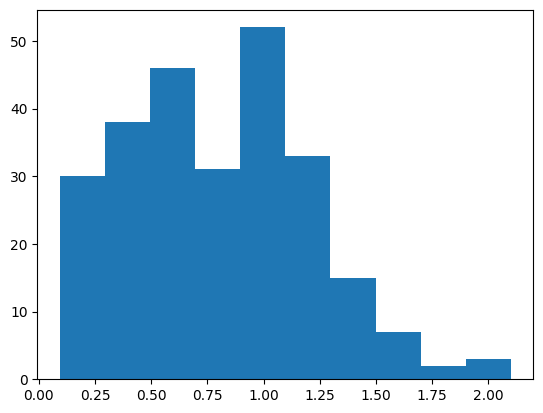

In [ ]:
# plt.hist(np.median(z_samples,axis=1))
# # plt.hist(events0_inj)

(array([1.00000e+01, 2.33000e+02, 1.37000e+03, 4.16900e+03, 9.25400e+03,
        1.78740e+04, 4.89990e+04, 1.52746e+05, 5.31444e+05, 9.58901e+05]),
 array([0.24428708, 0.31985836, 0.39542965, 0.47100093, 0.54657222,
        0.6221435 , 0.69771479, 0.77328607, 0.84885735, 0.92442864,
        0.99999992]),
 <BarContainer object of 10 artists>)

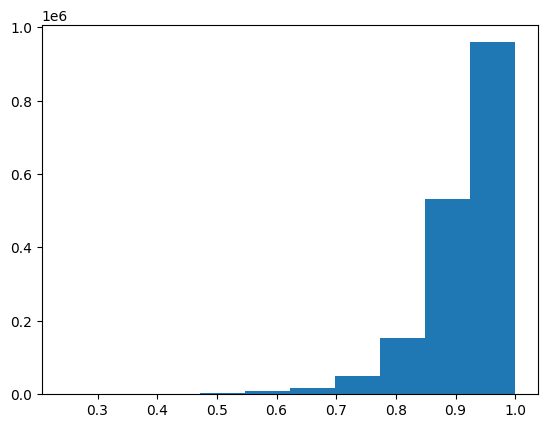

In [ ]:
# # mtotz_obs0 = chirpmz_obs0 / ((eta_obs0**(3/5)))
    
# # sqrt_term0 = np.sqrt(1 - 4*eta_obs0)

# # m1z_obs0=0.5 * mtotz_obs0 * (1 + sqrt_term0)
# # m2z_obs0=0.5 * mtotz_obs0 * (1 - sqrt_term0)

# # dl_obs0=(snr_interp(np.array([m1z_obs0,m2z_obs0]).T)*theta_obs0/snrs_obs0)*Dfix

# # z_obs0=zs_dl_spline(dl_obs0)

# # mtot_obs0=mtotz_obs0/(1.+z_obs0)

# # q_obs0=m2z_obs0/m1z_obs0

# # print(np.amin(mtot_obs0),np.amax(mtot_obs0))


# plt.hist(q_obs)

(array([2.112000e+03, 2.156490e+05, 1.255289e+06, 1.904760e+05,
        4.730000e+04, 9.612000e+03, 2.835000e+03, 1.166000e+03,
        4.520000e+02, 1.090000e+02]),
 array([1.45665574, 1.94406587, 2.431476  , 2.91888612, 3.40629625,
        3.89370637, 4.3811165 , 4.86852662, 5.35593675, 5.84334688,
        6.330757  ]),
 <BarContainer object of 10 artists>)

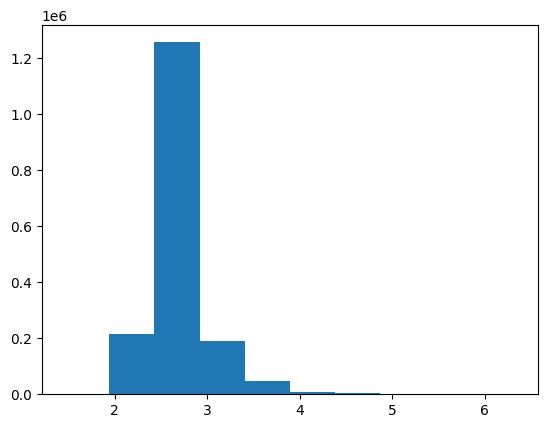

In [ ]:
# plt.hist(mtot_obs)

In [ ]:
plt.hist(events0[:num_events_1,1])

In [ ]:
plt.hist(events0[num_events_1:,1])

In [ ]:
mtot_means=np.mean(mtot_obs.reshape((len(snrs_obs0),nsamples_ev)),axis=1)

plt.hist(mtot_means)

In [ ]:
plt.scatter(z_obs0,snrs_obs0)

In [ ]:
mtot_grid=np.linspace(1,5,100)
snrs_mtot_grid=np.zeros(100)
for i in range(100):
    snrs_mtot_grid[i]=snr_interp(np.array([mtot_grid[i]/2,mtot_grid[i]/2]).T)

plt.plot(mtot_grid,snrs_mtot_grid)

In [ ]:
q_grid=np.linspace(0.2,1,100)
snrs_q_grid=np.zeros(100)
for i in range(100):
    snrs_q_grid[i]=snr_interp(np.array([3/(1+q_grid[i]),3*q_grid[i]/(1+q_grid[i])]).T)

plt.plot(q_grid,snrs_q_grid)

In [ ]:
# len(snrs_obs0)

122

In [ ]:
# name_out='samples_test_alpha_%1.1f'%(-params['alpha'])

# if sample_in_q==1:
#     name_out+='_sample_in_q'

# if more_events==1:
#     name_out+='_more_events'

# if small_errors==1:
#     name_out+='_small_errors'

    
# np.savez(name_out+'.npz',mtot_obs=mtot_obs,q_obs=q_obs,z_obs=z_obs,priors=priors,events0=events0,events=events,events_obs0=events_obs0,nsamples_ev=nsamples_ev,nobs=len(snrs_obs0),num_events_1=num_events_1)

In [ ]:
# name_out

'samples_test_alpha_0.5_sample_in_q_more_events'

In [ ]:
# events0_test,num_events_1=utils.draw_events(1000000,params,settings)


# zs_events0_test=events0_test[:,2]
# dl_events0_test=dl_zs_spline(zs_events0_test)
# mtots_events0_test=events0_test[:,0]
# qs_events0_test=events0_test[:,1]
# m1s_events0_test=mtots_events0_test/(1.+qs_events0_test)
# m2s_events0_test=mtots_events0_test*qs_events0_test/(1.+qs_events0_test)
# theta_events0_test=draw_thetas(len(zs_events0_test))

# snrs0_test=snr_interp(np.array([m1s_events0_test*(1.+zs_events0_test),m2s_events0_test*(1.+zs_events0_test)]).T)*theta_events0_test*Dfix/dl_events0_test

# ints=np.zeros(len(snrs0_test))
# ints[snrs0_test>snr_th]=1

# var=(((ints**2).sum() / (len(snrs0_test) - 1) - np.mean(ints)**2) / len(snrs0_test))

# # snrs_test=snrs0_test+np.random.normal(0,1,len(snrs0_test))

# print(np.mean(ints),var)

0.11038 9.819636598011037e-08


In [ ]:
# pdf_mtot1=utils.gauss_pdf(mtots_inj,params['mu_mtot_1'],params['sigma_mtot_1'])
# pdf_mtot2=utils.gauss_pdf(mtots_inj,params['mu_mtot_2'],params['sigma_mtot_2'])

# pdf_sigma_q_1=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_1'],params['sigma_q_1'],0.00,1)
# pdf_sigma_q_2=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_2'],params['sigma_q_2'],0.00,1)

# pdf_z_1_grid=utils.pdf_zmerge(zs_grid,params['tdelay_min'],params['tdelay_max'],params['alpha'],settings,force_norm=True)
# pdf_z_2_grid=utils.pdf_zmerge(zs_grid,params['tdelay'],params['tdelay']+0.0001,-2,settings,force_norm=True)

# # print(np.trapezoid(pdf_z_1_grid,x=zs_grid))
# # print(np.trapezoid(pdf_z_2_grid,x=zs_grid))

# pdf_z_1_spline=spline(zs_grid,pdf_z_1_grid)
# pdf_z_2_spline=spline(zs_grid,pdf_z_2_grid)


# pdf=params['mix_coeff']*pdf_mtot1*pdf_sigma_q_1*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_mtot2*pdf_sigma_q_2*pdf_z_2_spline(zs_inj)


# var=(((pdf/priors_inj**2).sum() / (ninj - 1) - (np.sum(pdf/priors_inj)/ninj)**2) / ninj)

# print(np.sum(pdf/priors_inj)/ninj)

# print(var)

/home/alexandretoubiana/Dropbox/Bicocca/ns_pop/utils.py:147: RuntimeWarning: divide by zero encountered in log
  za = (np.log(a) - np.log(mu)) / sigma


0.11267399805317499
4.0674021498318157e-07


In [ ]:
# pdet_draw_pop=np.zeros(100)

# for i in tqdm(range(100)):

#     events0_test,num_events_1=utils.draw_events(100000,params,settings)


#     zs_events0_test=events0_test[:,2]
#     dl_events0_test=dl_zs_spline(zs_events0_test)
#     mtots_events0_test=events0_test[:,0]
#     qs_events0_test=events0_test[:,1]
#     m1s_events0_test=mtots_events0_test/(1.+qs_events0_test)
#     m2s_events0_test=mtots_events0_test*qs_events0_test/(1.+qs_events0_test)
#     theta_events0_test=draw_thetas(len(zs_events0_test))

#     snrs0_test=snr_interp(np.array([m1s_events0_test*(1.+zs_events0_test),m2s_events0_test*(1.+zs_events0_test)]).T)*theta_events0_test*Dfix/dl_events0_test+np.random.normal(0,1,100000)

#     ints=np.zeros(len(snrs0_test))
#     ints[snrs0_test>snr_th]=1

#     pdet_draw_pop[i]=np.mean(ints)

#     # var=(((ints**2).sum() / (len(snrs0_test) - 1) - np.mean(ints)**2) / len(snrs0_test))


100%|██████████| 100/100 [01:26<00:00,  1.16it/s]


In [ ]:
# 

In [ ]:
# pdet_reweight_flat_z=np.zeros(100)
# injections_flat_z=1

# for i in tqdm(range(100)):

#     if injections_pop==1:
#         # num_inj_1=np.random.binomial(ninj, params['mix_coeff'])
#         # num_inj_2=ninj-num_inj_1

#         # zs_inj0=np.zeros(ninj)

#         # zs_inj0[:num_inj_1]=utils.draw_z_merge(num_inj_1,utils.draw_delay_pl,settings,params) 
#         # zs_inj0[num_inj_1:]=utils.draw_z_merge(num_inj_2,utils.draw_delta_delay,settings,params)

#         events0_inj,num_events_inj_1=utils.draw_events(ninj,params,settings)
        

#         mtots_inj0=events0_inj[:,0]
#         qs_inj0=events0_inj[:,1]

#         m1s_inj0=mtots_inj0/(1.+qs_inj0)
#         m2s_inj0=mtots_inj0*qs_inj0/(1.+qs_inj0)

#         zs_inj0=events0_inj[:,2]


#     elif injections_flat_z==1:

#         m_inj_min,m_inj_max=0.5,3.
#         m1s_inj0=np.random.uniform(m_inj_min,m_inj_max,ninj)


#         m2s_inj0=np.sqrt(np.random.uniform(0,1,ninj)*(m1s_inj0**2-m_inj_min**2)+m_inj_min**2)

#         zs_inj0=np.random.uniform(0,zmax,ninj)

        
#     else:

#         m_inj_min,m_inj_max=0.5,3.
#         m1s_inj0=np.random.uniform(m_inj_min,m_inj_max,ninj)


#         m2s_inj0=np.sqrt(np.random.uniform(0,1,ninj)*(m1s_inj0**2-m_inj_min**2)+m_inj_min**2)
        
#         pdf_z=dVc_spl(zs_grid)
#         cdf_z=np.cumsum(pdf_z)
#         cdf_z/=cdf_z[-1]

#         inv_cdf_spline=spline(cdf_z,zs_grid)
#         pdf_z_spline=spline(zs_grid,pdf_z/np.trapezoid(pdf_z,x=zs_grid))

#         zs_inj0=inv_cdf_spline(np.random.uniform(0,1,ninj))




#     thetas_inj0=draw_thetas(ninj)

#     dls_injs=dl_zs_spline(zs_inj0)


#     snrs_inj0=snr_interp(np.array([m1s_inj0*(1+zs_inj0),m2s_inj0*(1+zs_inj0)]).T)*thetas_inj0*Dfix/dls_injs


#     snrs_inj=snrs_inj0+np.random.normal(0,1,ninj)
#     # nfix=np.sum(snrs_inj<0.)
#     # while nfix>0:
#     #     print(nfix)
#     #     inds_fix=np.argwhere(snrs_inj<0)[:,0]

#     #     snrs_inj[inds_fix]=snrs_inj0[inds_fix]+np.random.normal(0,1,nfix)

#     #     nfix=np.sum(snrs_inj<0.)


#     mtots_inj0=m1s_inj0+m2s_inj0
#     qs_inj0=m2s_inj0/m1s_inj0

#     zs_inj=zs_inj0[snrs_inj>snr_th]
#     mtots_inj=mtots_inj0[snrs_inj>snr_th]
#     qs_inj=qs_inj0[snrs_inj>snr_th]
# # 
#     # print('computing priors')

#     if injections_pop==1:

#         print('computing mtot')
#         pdf_mtot_1=utils.gauss_pdf(mtots_inj,params['mu_mtot_1'],params['sigma_mtot_1'])
#         pdf_mtot_2=utils.gauss_pdf(mtots_inj,params['mu_mtot_2'],params['sigma_mtot_2'])

#         print('computing q')
#         pdf_q_1=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_1'],params['sigma_q_1'],0,1)
#         pdf_q_2=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_2'],params['sigma_q_2'],0,1)

#         print('computing z')
#         pdf_z_1_grid=utils.pdf_zmerge(zs_grid,params['tdelay_min'],params['tdelay_max'],params['alpha'],settings,force_norm=True)
#         pdf_z_2_grid=utils.pdf_zmerge(zs_grid,params['tdelay'],params['tdelay']+0.001,-2,settings,force_norm=True)

#         pdf_z_1_spline=spline(zs_grid,pdf_z_1_grid)
#         pdf_z_2_spline=spline(zs_grid,pdf_z_2_grid)
#         # pdf_z_grid=params['mix_coeff']*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_z_2_spline(zs_inj)


#         priors_inj=params['mix_coeff']*pdf_mtot_1*pdf_q_1*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_mtot_2*pdf_q_2*pdf_z_2_spline(zs_inj)

#     elif injections_flat_z==1:

#         priors_inj=(mtots_inj/((1.+qs_inj)**2))*(2*m2s_inj0[snrs_inj>snr_th]/(m1s_inj0[snrs_inj>snr_th]**2-m_inj_min**2))*(1./zmax)*(1./(m_inj_max-m_inj_min))
        
#     else:

#         priors_inj=(mtots_inj/((1.+qs_inj)**2))*(2*m2s_inj0[snrs_inj>snr_th]/(m1s_inj0[snrs_inj>snr_th]**2-m_inj_min**2))*pdf_z_spline(zs_inj)*(1./(m_inj_max-m_inj_min))
    


#     pdf_mtot1=utils.gauss_pdf(mtots_inj,params['mu_mtot_1'],params['sigma_mtot_1'])
#     pdf_mtot2=utils.gauss_pdf(mtots_inj,params['mu_mtot_2'],params['sigma_mtot_2'])

#     pdf_sigma_q_1=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_1'],params['sigma_q_1'],0.00,1)
#     pdf_sigma_q_2=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_2'],params['sigma_q_2'],0.00,1)

#     pdf_z_1_grid=utils.pdf_zmerge(zs_grid,params['tdelay_min'],params['tdelay_max'],params['alpha'],settings,force_norm=True)
#     pdf_z_2_grid=utils.pdf_zmerge(zs_grid,params['tdelay'],params['tdelay']+0.0001,-2,settings,force_norm=True)

#     # print(np.trapezoid(pdf_z_1_grid,x=zs_grid))
#     # print(np.trapezoid(pdf_z_2_grid,x=zs_grid))

#     pdf_z_1_spline=spline(zs_grid,pdf_z_1_grid)
#     pdf_z_2_spline=spline(zs_grid,pdf_z_2_grid)


#     pdf=params['mix_coeff']*pdf_mtot1*pdf_sigma_q_1*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_mtot2*pdf_sigma_q_2*pdf_z_2_spline(zs_inj)


#     var=(((pdf/priors_inj**2).sum() / (ninj - 1) - (np.sum(pdf/priors_inj)/ninj)**2) / ninj)

#     pdet_reweight_flat_z[i]=np.sum(pdf/priors_inj)/ninj




  0%|          | 0/100 [00:00<?, ?it/s]/home/alexandretoubiana/Dropbox/Bicocca/ns_pop/utils.py:147: RuntimeWarning: divide by zero encountered in log
  za = (np.log(a) - np.log(mu)) / sigma
100%|██████████| 100/100 [01:41<00:00,  1.01s/it]


In [ ]:
# pdet_reweight_cvol=np.zeros(100)
# injections_flat_z=0

# for i in tqdm(range(100)):

#     if injections_pop==1:
#         # num_inj_1=np.random.binomial(ninj, params['mix_coeff'])
#         # num_inj_2=ninj-num_inj_1

#         # zs_inj0=np.zeros(ninj)

#         # zs_inj0[:num_inj_1]=utils.draw_z_merge(num_inj_1,utils.draw_delay_pl,settings,params) 
#         # zs_inj0[num_inj_1:]=utils.draw_z_merge(num_inj_2,utils.draw_delta_delay,settings,params)

#         events0_inj,num_events_inj_1=utils.draw_events(ninj,params,settings)
        

#         mtots_inj0=events0_inj[:,0]
#         qs_inj0=events0_inj[:,1]

#         m1s_inj0=mtots_inj0/(1.+qs_inj0)
#         m2s_inj0=mtots_inj0*qs_inj0/(1.+qs_inj0)

#         zs_inj0=events0_inj[:,2]


#     elif injections_flat_z==1:

#         m_inj_min,m_inj_max=0.5,3.
#         m1s_inj0=np.random.uniform(m_inj_min,m_inj_max,ninj)


#         m2s_inj0=np.sqrt(np.random.uniform(0,1,ninj)*(m1s_inj0**2-m_inj_min**2)+m_inj_min**2)

#         zs_inj0=np.random.uniform(0,zmax,ninj)

        
#     else:

#         m_inj_min,m_inj_max=0.5,3.
#         m1s_inj0=np.random.uniform(m_inj_min,m_inj_max,ninj)


#         m2s_inj0=np.sqrt(np.random.uniform(0,1,ninj)*(m1s_inj0**2-m_inj_min**2)+m_inj_min**2)
        
#         pdf_z=dVc_spl(zs_grid)
#         cdf_z=np.cumsum(pdf_z)
#         cdf_z/=cdf_z[-1]

#         inv_cdf_spline=spline(cdf_z,zs_grid)
#         pdf_z_spline=spline(zs_grid,pdf_z/np.trapezoid(pdf_z,x=zs_grid))

#         zs_inj0=inv_cdf_spline(np.random.uniform(0,1,ninj))




#     thetas_inj0=draw_thetas(ninj)

#     dls_injs=dl_zs_spline(zs_inj0)


#     snrs_inj0=snr_interp(np.array([m1s_inj0*(1+zs_inj0),m2s_inj0*(1+zs_inj0)]).T)*thetas_inj0*Dfix/dls_injs


#     snrs_inj=snrs_inj0+np.random.normal(0,1,ninj)
#     # nfix=np.sum(snrs_inj<0.)
#     # while nfix>0:
#     #     print(nfix)
#     #     inds_fix=np.argwhere(snrs_inj<0)[:,0]

#     #     snrs_inj[inds_fix]=snrs_inj0[inds_fix]+np.random.normal(0,1,nfix)

#     #     nfix=np.sum(snrs_inj<0.)


#     mtots_inj0=m1s_inj0+m2s_inj0
#     qs_inj0=m2s_inj0/m1s_inj0

#     zs_inj=zs_inj0[snrs_inj>snr_th]
#     mtots_inj=mtots_inj0[snrs_inj>snr_th]
#     qs_inj=qs_inj0[snrs_inj>snr_th]
# # 
#     # print('computing priors')

#     if injections_pop==1:

#         print('computing mtot')
#         pdf_mtot_1=utils.gauss_pdf(mtots_inj,params['mu_mtot_1'],params['sigma_mtot_1'])
#         pdf_mtot_2=utils.gauss_pdf(mtots_inj,params['mu_mtot_2'],params['sigma_mtot_2'])

#         print('computing q')
#         pdf_q_1=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_1'],params['sigma_q_1'],0,1)
#         pdf_q_2=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_2'],params['sigma_q_2'],0,1)

#         print('computing z')
#         pdf_z_1_grid=utils.pdf_zmerge(zs_grid,params['tdelay_min'],params['tdelay_max'],params['alpha'],settings,force_norm=True)
#         pdf_z_2_grid=utils.pdf_zmerge(zs_grid,params['tdelay'],params['tdelay']+0.001,-2,settings,force_norm=True)

#         pdf_z_1_spline=spline(zs_grid,pdf_z_1_grid)
#         pdf_z_2_spline=spline(zs_grid,pdf_z_2_grid)
#         # pdf_z_grid=params['mix_coeff']*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_z_2_spline(zs_inj)


#         priors_inj=params['mix_coeff']*pdf_mtot_1*pdf_q_1*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_mtot_2*pdf_q_2*pdf_z_2_spline(zs_inj)

#     elif injections_flat_z==1:

#         priors_inj=(mtots_inj/((1.+qs_inj)**2))*(2*m2s_inj0[snrs_inj>snr_th]/(m1s_inj0[snrs_inj>snr_th]**2-m_inj_min**2))*(1./zmax)*(1./(m_inj_max-m_inj_min))
        
#     else:

#         priors_inj=(mtots_inj/((1.+qs_inj)**2))*(2*m2s_inj0[snrs_inj>snr_th]/(m1s_inj0[snrs_inj>snr_th]**2-m_inj_min**2))*pdf_z_spline(zs_inj)*(1./(m_inj_max-m_inj_min))
    


#     pdf_mtot1=utils.gauss_pdf(mtots_inj,params['mu_mtot_1'],params['sigma_mtot_1'])
#     pdf_mtot2=utils.gauss_pdf(mtots_inj,params['mu_mtot_2'],params['sigma_mtot_2'])

#     pdf_sigma_q_1=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_1'],params['sigma_q_1'],0.00,1)
#     pdf_sigma_q_2=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_2'],params['sigma_q_2'],0.00,1)

#     pdf_z_1_grid=utils.pdf_zmerge(zs_grid,params['tdelay_min'],params['tdelay_max'],params['alpha'],settings,force_norm=True)
#     pdf_z_2_grid=utils.pdf_zmerge(zs_grid,params['tdelay'],params['tdelay']+0.0001,-2,settings,force_norm=True)

#     # print(np.trapezoid(pdf_z_1_grid,x=zs_grid))
#     # print(np.trapezoid(pdf_z_2_grid,x=zs_grid))

#     pdf_z_1_spline=spline(zs_grid,pdf_z_1_grid)
#     pdf_z_2_spline=spline(zs_grid,pdf_z_2_grid)


#     pdf=params['mix_coeff']*pdf_mtot1*pdf_sigma_q_1*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_mtot2*pdf_sigma_q_2*pdf_z_2_spline(zs_inj)


#     var=(((pdf/priors_inj**2).sum() / (ninj - 1) - (np.sum(pdf/priors_inj)/ninj)**2) / ninj)

#     pdet_reweight_cvol[i]=np.sum(pdf/priors_inj)/ninj




100%|██████████| 100/100 [01:53<00:00,  1.13s/it]


In [ ]:
# pdet_reweight_pop=np.zeros(100)
# injections_pop=1

# for i in tqdm(range(100)):

#     if injections_pop==1:
#         ninj=100000
#         # num_inj_1=np.random.binomial(ninj, params['mix_coeff'])
#         # num_inj_2=ninj-num_inj_1

#         # zs_inj0=np.zeros(ninj)

#         # zs_inj0[:num_inj_1]=utils.draw_z_merge(num_inj_1,utils.draw_delay_pl,settings,params) 
#         # zs_inj0[num_inj_1:]=utils.draw_z_merge(num_inj_2,utils.draw_delta_delay,settings,params)

#         events0_inj,num_events_inj_1=utils.draw_events(ninj,params,settings)
        

#         mtots_inj0=events0_inj[:,0]
#         qs_inj0=events0_inj[:,1]

#         m1s_inj0=mtots_inj0/(1.+qs_inj0)
#         m2s_inj0=mtots_inj0*qs_inj0/(1.+qs_inj0)

#         zs_inj0=events0_inj[:,2]


#     elif injections_flat_z==1:

#         m_inj_min,m_inj_max=0.5,3.
#         m1s_inj0=np.random.uniform(m_inj_min,m_inj_max,ninj)


#         m2s_inj0=np.sqrt(np.random.uniform(0,1,ninj)*(m1s_inj0**2-m_inj_min**2)+m_inj_min**2)

#         zs_inj0=np.random.uniform(0,zmax,ninj)

        
#     else:

#         m_inj_min,m_inj_max=0.5,3.
#         m1s_inj0=np.random.uniform(m_inj_min,m_inj_max,ninj)


#         m2s_inj0=np.sqrt(np.random.uniform(0,1,ninj)*(m1s_inj0**2-m_inj_min**2)+m_inj_min**2)
        
#         pdf_z=dVc_spl(zs_grid)
#         cdf_z=np.cumsum(pdf_z)
#         cdf_z/=cdf_z[-1]

#         inv_cdf_spline=spline(cdf_z,zs_grid)
#         pdf_z_spline=spline(zs_grid,pdf_z/np.trapezoid(pdf_z,x=zs_grid))

#         zs_inj0=inv_cdf_spline(np.random.uniform(0,1,ninj))




#     thetas_inj0=draw_thetas(ninj)

#     dls_injs=dl_zs_spline(zs_inj0)


#     snrs_inj0=snr_interp(np.array([m1s_inj0*(1+zs_inj0),m2s_inj0*(1+zs_inj0)]).T)*thetas_inj0*Dfix/dls_injs


#     snrs_inj=snrs_inj0+np.random.normal(0,1,ninj)
#     # nfix=np.sum(snrs_inj<0.)
#     # while nfix>0:
#     #     print(nfix)
#     #     inds_fix=np.argwhere(snrs_inj<0)[:,0]

#     #     snrs_inj[inds_fix]=snrs_inj0[inds_fix]+np.random.normal(0,1,nfix)

#     #     nfix=np.sum(snrs_inj<0.)


#     mtots_inj0=m1s_inj0+m2s_inj0
#     qs_inj0=m2s_inj0/m1s_inj0

#     zs_inj=zs_inj0[snrs_inj>snr_th]
#     mtots_inj=mtots_inj0[snrs_inj>snr_th]
#     qs_inj=qs_inj0[snrs_inj>snr_th]
# # 
#     # print('computing priors')

#     if injections_pop==1:

#         print('computing mtot')
#         pdf_mtot_1=utils.gauss_pdf(mtots_inj,params['mu_mtot_1'],params['sigma_mtot_1'])
#         pdf_mtot_2=utils.gauss_pdf(mtots_inj,params['mu_mtot_2'],params['sigma_mtot_2'])

#         print('computing q')
#         pdf_q_1=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_1'],params['sigma_q_1'],0,1)
#         pdf_q_2=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_2'],params['sigma_q_2'],0,1)

#         print('computing z')
#         pdf_z_1_grid=utils.pdf_zmerge(zs_grid,params['tdelay_min'],params['tdelay_max'],params['alpha'],settings,force_norm=True)
#         pdf_z_2_grid=utils.pdf_zmerge(zs_grid,params['tdelay'],params['tdelay']+0.001,-2,settings,force_norm=True)

#         pdf_z_1_spline=spline(zs_grid,pdf_z_1_grid)
#         pdf_z_2_spline=spline(zs_grid,pdf_z_2_grid)
#         # pdf_z_grid=params['mix_coeff']*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_z_2_spline(zs_inj)


#         priors_inj=params['mix_coeff']*pdf_mtot_1*pdf_q_1*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_mtot_2*pdf_q_2*pdf_z_2_spline(zs_inj)

#     elif injections_flat_z==1:

#         priors_inj=(mtots_inj/((1.+qs_inj)**2))*(2*m2s_inj0[snrs_inj>snr_th]/(m1s_inj0[snrs_inj>snr_th]**2-m_inj_min**2))*(1./zmax)*(1./(m_inj_max-m_inj_min))
        
#     else:

#         priors_inj=(mtots_inj/((1.+qs_inj)**2))*(2*m2s_inj0[snrs_inj>snr_th]/(m1s_inj0[snrs_inj>snr_th]**2-m_inj_min**2))*pdf_z_spline(zs_inj)*(1./(m_inj_max-m_inj_min))
    


#     pdf_mtot1=utils.gauss_pdf(mtots_inj,params['mu_mtot_1'],params['sigma_mtot_1'])
#     pdf_mtot2=utils.gauss_pdf(mtots_inj,params['mu_mtot_2'],params['sigma_mtot_2'])

#     pdf_sigma_q_1=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_1'],params['sigma_q_1'],0.00,1)
#     pdf_sigma_q_2=utils.truncated_lognorm_pdf(qs_inj,params['mu_q_2'],params['sigma_q_2'],0.00,1)

#     pdf_z_1_grid=utils.pdf_zmerge(zs_grid,params['tdelay_min'],params['tdelay_max'],params['alpha'],settings,force_norm=True)
#     pdf_z_2_grid=utils.pdf_zmerge(zs_grid,params['tdelay'],params['tdelay']+0.0001,-2,settings,force_norm=True)

#     # print(np.trapezoid(pdf_z_1_grid,x=zs_grid))
#     # print(np.trapezoid(pdf_z_2_grid,x=zs_grid))

#     pdf_z_1_spline=spline(zs_grid,pdf_z_1_grid)
#     pdf_z_2_spline=spline(zs_grid,pdf_z_2_grid)


#     pdf=params['mix_coeff']*pdf_mtot1*pdf_sigma_q_1*pdf_z_1_spline(zs_inj)+(1.-params['mix_coeff'])*pdf_mtot2*pdf_sigma_q_2*pdf_z_2_spline(zs_inj)


#     var=(((pdf/priors_inj**2).sum() / (ninj - 1) - (np.sum(pdf/priors_inj)/ninj)**2) / ninj)

#     pdet_reweight_pop[i]=np.sum(pdf/priors_inj)/ninj




  0%|          | 0/100 [00:00<?, ?it/s]

computing mtot
computing q
computing z


  1%|          | 1/100 [00:02<03:34,  2.17s/it]

computing mtot
computing q
computing z


  2%|▏         | 2/100 [00:04<03:31,  2.16s/it]

...

 98%|█████████▊| 98/100 [03:24<00:04,  2.19s/it]

computing mtot
computing q
computing z


 99%|█████████▉| 99/100 [03:26<00:02,  2.15s/it]

computing mtot
computing q
computing z


100%|██████████| 100/100 [03:28<00:00,  2.08s/it]


<Axes: ylabel='Count'>

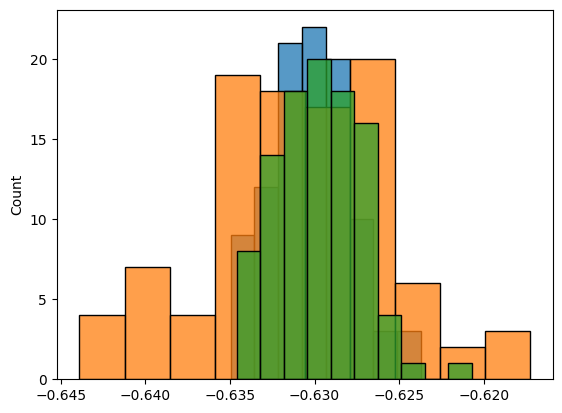

In [ ]:
# sns.histplot(np.log10(pdet_draw_pop))
# sns.histplot(np.log10(pdet_reweight_flat_z))
# sns.histplot(np.log10(pdet_reweight_pop))
# # sns.histplot(np.log10(pdet_reweight_cvol))

In [ ]:
# 